# Proyecto ML — Visión Artificial
## BreastMNIST: Clasificación Binaria de Cáncer de Mama en Ultrasonido
### CINF104 — Universidad Andrés Bello | 2026

| Campo | Valor |
|---|---|
| Dataset | BreastMNIST (MedMNIST v2) |
| Tarea | Clasificación binaria: Maligno (0) vs Normal/Benigno (1) |
| Resolución Entrega 1 | 28×28 píxeles, escala de grises |
| Framework | PyTorch |

---
### Índice de Módulos
| Módulo | Contenido |
|---|---|
| M0 | Instalación de dependencias |
| M1 | ⚙️ Configuración global — **editar aquí** |
| M2 | Contexto clínico y exploración del dataset |
| M3 | DataLoaders y transformaciones |
| M4 | Funciones de entrenamiento y métricas |
| M5 | Modelo A — CNN Casera (baseline) |
| M6 | Modelo B — ResNet18 Fine-Tuning |
| M7 | Comparación de resultados |
| M8 | Conclusiones |

---
## M0 — Instalación
> Ejecutar una sola vez al iniciar el entorno Colab.

In [1]:
!pip install medmnist -q

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights
import medmnist
from medmnist import BreastMNIST, INFO
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)
import warnings
warnings.filterwarnings('ignore')

print(f'PyTorch  : {torch.__version__}')
print(f'MedMNIST : {medmnist.__version__}')
print(f'CUDA     : {torch.cuda.is_available()}')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.0 MB/s eta 0:00:00
PyTorch  : 2.11.0+cu128
MedMNIST : 3.0.2
CUDA     : True


---
## M1 — Configuración Global

> **Este es el único módulo que debes editar para modificar hiperparámetros.**  
> Después de cambiar cualquier valor, re-ejecuta desde **M3** en adelante.

### ¿Por qué centralizar la configuración?

En experimentos de Machine Learning es fundamental poder **reproducir y comparar resultados**.  
Si los hiperparámetros están dispersos en el código, un cambio en `BATCH_SIZE` puede  
afectar partes del código que no se actualizaron, generando resultados inconsistentes.

Centralizar en un solo bloque permite:
- Cambiar una variable y propagarla automáticamente a todos los módulos
- Documentar claramente qué configuración produjo cada resultado
- Facilitar la comparación entre experimentos (ej: Entrega 1 vs Entrega 2)

In [2]:
# ============================================================
#   CONFIGURACIÓN GLOBAL — EDITAR AQUÍ
# ============================================================

# --- Reproducibilidad ---
SEED         = 42      # Fija aleatoriedad para resultados reproducibles

# --- Dataset ---
IMAGE_SIZE   = 28      # Resolución: 28 (Entrega 1) | 128 (Entrega 2)
N_CHANNELS   = 1       # 1 = escala de grises (BreastMNIST)
N_CLASSES    = 2       # 0 = Maligno | 1 = Normal/Benigno  (convención MedMNIST)
CLASS_NAMES  = ['Maligno', 'Normal/Benigno']

# --- DataLoader ---
BATCH_SIZE   = 64      # Reducir a 32 si hay problemas de memoria GPU
NUM_WORKERS  = 2

# --- Data Augmentation (solo train) ---
AUG_HFLIP    = True    # Flip horizontal aleatorio
AUG_ROTATION = 10      # Grados de rotación máxima (0 = desactivado)

# --- Entrenamiento ---
EPOCHS_CNN    = 15     # Épocas CNN Casera
EPOCHS_RESNET = 15     # Épocas ResNet18
LR_CNN        = 5e-4   # Learning rate CNN (reducido para estabilidad)
LR_RESNET     = 1e-4   # Learning rate ResNet (más bajo por fine-tuning)
LR_STEP       = 5      # Reducir LR cada N épocas
LR_GAMMA      = 0.5    # Factor de reducción del LR

# --- ResNet18 ---
RESNET_FINETUNE_ALL = True  # True = fine-tuning completo
                             # False = solo última capa

# ============================================================

# --- Manejo de desbalanceo ---
# MedMNIST BreastMNIST: 0=Maligno (minoritario), 1=Normal/Benigno (mayoritario)
# Ratio ~2.71:1 => penalizamos mas los errores en clase Maligno (minoritaria)
CLASS_WEIGHT        = torch.tensor([1.5, 1.0])   # [peso_Maligno, peso_Normal]
# Peso moderado: 2.71 era demasiado agresivo con 546 imgs => colapsaba a predecir siempre Maligno
WEIGHT_DECAY_RESNET = 1e-3  # L2 regularizacion para ResNet (reduce overfitting)

torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print('Configuracion activa:')
print(f'  Dispositivo       : {DEVICE}')
print(f'  Resolucion        : {IMAGE_SIZE}x{IMAGE_SIZE} px')
print(f'  Batch size        : {BATCH_SIZE}')
print(f'  Epocas CNN        : {EPOCHS_CNN}')
print(f'  Epocas ResNet     : {EPOCHS_RESNET}')
print(f'  LR CNN            : {LR_CNN}')
print(f'  LR ResNet         : {LR_RESNET}')
print(f'  LR scheduler      : step={LR_STEP}, gamma={LR_GAMMA}')
print(f'  Aug flip          : {AUG_HFLIP}')
print(f'  Aug rotacion      : {AUG_ROTATION} grados')
print(f'  ResNet finetune   : {"completo" if RESNET_FINETUNE_ALL else "solo ultima capa"}')
print(f'  Class weights     : {CLASS_WEIGHT.tolist()} [Maligno, Normal]')
print(f'  Weight decay ResNet: {WEIGHT_DECAY_RESNET}')

Configuracion activa:
  Dispositivo       : cuda
  Resolucion        : 28x28 px
  Batch size        : 64
  Epocas CNN        : 15
  Epocas ResNet     : 15
  LR CNN            : 0.0005
  LR ResNet         : 0.0001
  LR scheduler      : step=5, gamma=0.5
  Aug flip          : True
  Aug rotacion      : 10 grados
  ResNet finetune   : completo
  Class weights     : [1.5, 1.0] [Maligno, Normal]
  Weight decay ResNet: 0.001


---
## M2 — Contexto Clínico y Exploración del Dataset

### Importancia del contexto clínico en ML médico

Antes de entrenar cualquier modelo, es fundamental entender el **problema clínico**  
que se está resolviendo. Esto determina:
- Qué métricas son más relevantes
- Qué tipo de errores son más costosos
- Qué transformaciones de datos son válidas

En este caso, no detectar una neumonía real (**falso negativo**) es más peligroso  
que dar una alarma innecesaria (**falso positivo**). Eso guía todas las decisiones  
de diseño del experimento.

In [3]:
print('=== CONTEXTO CLÍNICO ===')
print('''
ENFERMEDAD: Cáncer de Mama
  Tumor maligno originado en el tejido mamario. Segunda causa de
  muerte por cáncer en mujeres a nivel mundial.

DIAGNÓSTICO: Ultrasonido de mama
  Técnica de imagen no invasiva que usa ondas de sonido de alta frecuencia.
  Permite distinguir masas sólidas (potencialmente malignas) de quistes
  (generalmente benignos).

MOTIVACIÓN DEL SISTEMA AUTOMATIZADO:
  - Apoyar radiólogos en la lectura de ecografías mamarias
  - Reducir variabilidad inter-observador en el diagnóstico
  - Mejorar acceso a screening en zonas con escasez de especialistas

DATASET: BreastMNIST
  Origen: Breast Ultrasound Images Dataset — Kaggle
  Preprocesamiento: reescalado a 28x28 px, escala de grises
  Clases: 0 = Maligno | 1 = Normal/Benigno  (convención oficial MedMNIST)
''')

info = INFO['breastmnist']
print('Metadata oficial MedMNIST:')
for k, v in info.items():
    print(f'  {k}: {v}')

=== CONTEXTO CLÍNICO ===

ENFERMEDAD: Cáncer de Mama
  Tumor maligno originado en el tejido mamario. Segunda causa de
  muerte por cáncer en mujeres a nivel mundial.

DIAGNÓSTICO: Ultrasonido de mama
  Técnica de imagen no invasiva que usa ondas de sonido de alta frecuencia.
  Permite distinguir masas sólidas (potencialmente malignas) de quistes
  (generalmente benignos).

MOTIVACIÓN DEL SISTEMA AUTOMATIZADO:
  - Apoyar radiólogos en la lectura de ecografías mamarias
  - Reducir variabilidad inter-observador en el diagnóstico
  - Mejorar acceso a screening en zonas con escasez de especialistas

DATASET: BreastMNIST
  Origen: Breast Ultrasound Images Dataset — Kaggle
  Preprocesamiento: reescalado a 28x28 px, escala de grises
  Clases: 0 = Maligno | 1 = Normal/Benigno  (convención oficial MedMNIST)

Metadata oficial MedMNIST:
  python_class: BreastMNIST
  description: The BreastMNIST is based on a dataset of 780 breast ultrasound images. It is categorized into 3 classes: normal, benign,

In [4]:
transform_base = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[.5], std=[.5])
])

ds_train = BreastMNIST(split='train', transform=transform_base, download=True)
ds_val   = BreastMNIST(split='val',   transform=transform_base, download=True)
ds_test  = BreastMNIST(split='test',  transform=transform_base, download=True)

print(f'Split     | Imagenes')
print(f'----------+---------')
print(f'Train     | {len(ds_train)}')
print(f'Val       | {len(ds_val)}')
print(f'Test      | {len(ds_test)}')
print(f'Total     | {len(ds_train)+len(ds_val)+len(ds_test)}')

100%|██████████| 560k/560k [00:00<00:00, 739kB/s]

Split     | Imagenes
----------+---------
Train     | 546
Val       | 78
Test      | 156
Total     | 780


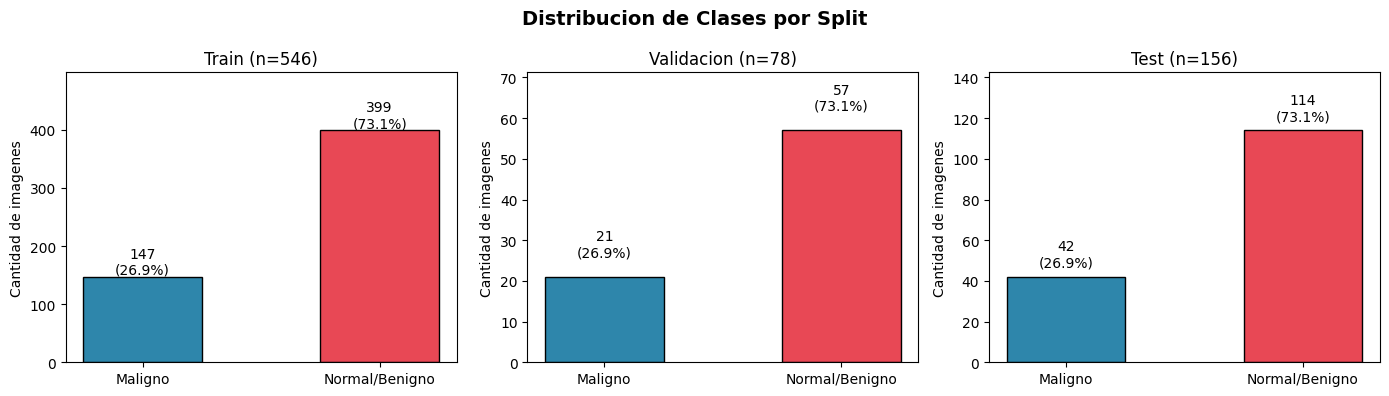

Ratio Normal/Maligno en train: 2.71:1  (hay mas casos normales que malignos)
ATENCION: Dataset desbalanceado. Se usara F1-Score ademas de Accuracy.


In [5]:
def get_labels(dataset):
    return [int(dataset[i][1]) for i in range(len(dataset))]

labels_train = get_labels(ds_train)
labels_val   = get_labels(ds_val)
labels_test  = get_labels(ds_test)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Distribucion de Clases por Split', fontsize=14, fontweight='bold')

for ax, labs, title in zip(axes,
                            [labels_train, labels_val, labels_test],
                            ['Train', 'Validacion', 'Test']):
    counts = [labs.count(0), labs.count(1)]
    bars = ax.bar(CLASS_NAMES, counts,
                  color=['#2E86AB', '#E84855'], edgecolor='black', width=0.5)
    for bar, c in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 5,
                f'{c}\n({c/sum(counts)*100:.1f}%)',
                ha='center', fontsize=10)
    ax.set_title(f'{title} (n={sum(counts)})')
    ax.set_ylabel('Cantidad de imagenes')
    ax.set_ylim(0, max(counts) * 1.25)

plt.tight_layout()
plt.savefig('distribucion_clases.png', dpi=120, bbox_inches='tight')
plt.show()

# Detectar desbalanceo
# 0=Maligno, 1=Normal/Benigno segun MedMNIST
ratio = labels_train.count(1) / max(labels_train.count(0), 1)
print(f'Ratio Normal/Maligno en train: {ratio:.2f}:1  (hay mas casos normales que malignos)')
if ratio > 1.5:
    print('ATENCION: Dataset desbalanceado. Se usara F1-Score ademas de Accuracy.')

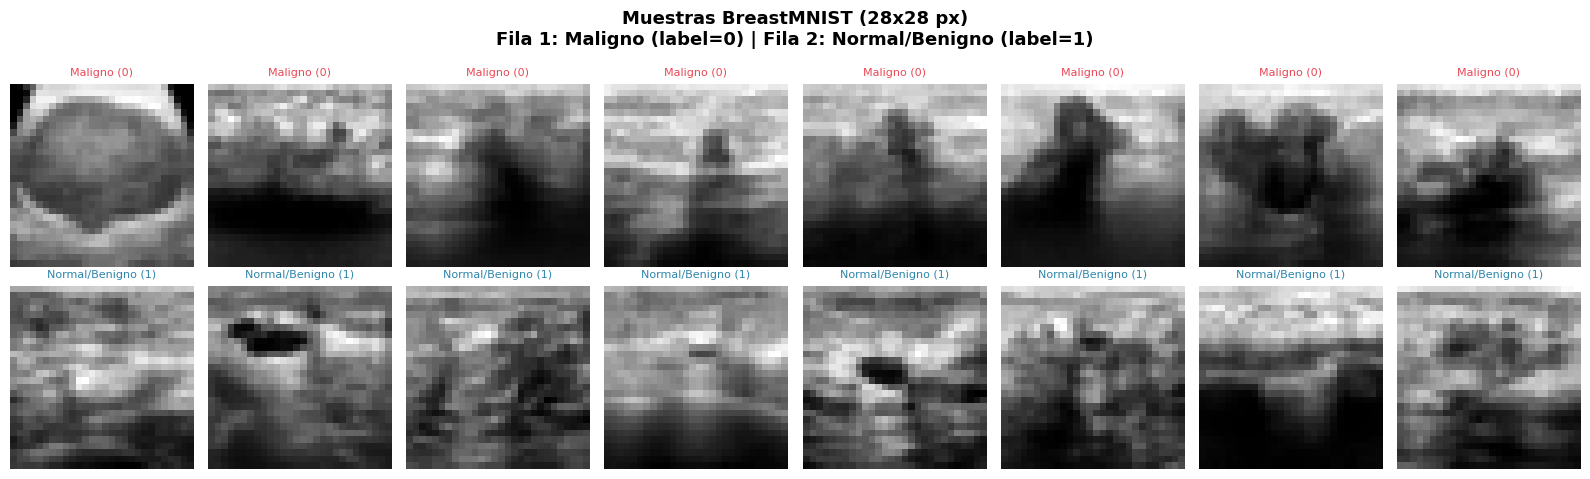

Observacion: a 28x28 px las masas ecograficas son dificiles
de distinguir visualmente, lo que hace el problema desafiante.


In [6]:
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
fig.suptitle('Muestras BreastMNIST (28x28 px)\nFila 1: Maligno (label=0) | Fila 2: Normal/Benigno (label=1)',
             fontsize=13, fontweight='bold')

# MedMNIST: label 0 = Maligno, label 1 = Normal/Benigno
maligno_imgs, normal_imgs = [], []
for img, label in ds_train:
    if int(label) == 0 and len(maligno_imgs) < 8:
        maligno_imgs.append(img)
    elif int(label) == 1 and len(normal_imgs) < 8:
        normal_imgs.append(img)
    if len(maligno_imgs) == 8 and len(normal_imgs) == 8:
        break

for col, img in enumerate(maligno_imgs):
    axes[0, col].imshow(img.squeeze(), cmap='gray')
    axes[0, col].axis('off')
    axes[0, col].set_title('Maligno (0)', fontsize=8, color='#E84855')

for col, img in enumerate(normal_imgs):
    axes[1, col].imshow(img.squeeze(), cmap='gray')
    axes[1, col].axis('off')
    axes[1, col].set_title('Normal/Benigno (1)', fontsize=8, color='#2E86AB')

plt.tight_layout()
plt.savefig('muestras_dataset.png', dpi=120, bbox_inches='tight')
plt.show()
print('Observacion: a 28x28 px las masas ecograficas son dificiles')
print('de distinguir visualmente, lo que hace el problema desafiante.')

---
## M3 — DataLoaders y Transformaciones

### ¿Por qué se aplica Data Augmentation?

BreastMNIST tiene ~4.700 imágenes de entrenamiento. Para redes convolucionales  
este volumen es moderado, lo que aumenta el riesgo de **overfitting** (memorizar  
el set de entrenamiento en lugar de aprender patrones generalizables).

El augmentation genera variaciones artificiales de cada imagen durante el entrenamiento,  
actuando como si tuviéramos más datos:

```
Imagen original → [flip horizontal] → nueva variación válida
Imagen original → [rotación ±10°]  → nueva variación válida
```

**Justificación clínica de las transformaciones elegidas:**
- **Flip horizontal:** las ecografías mamarias pueden adquirirse en ambas orientaciones
- **Rotación ±10°:** el transductor puede posicionarse con leve inclinación
  durante la exploración ecográfica

> ⚠️ El augmentation se aplica **solo al set de entrenamiento**.  
> Validación y test usan solo normalización para evaluar el modelo real.

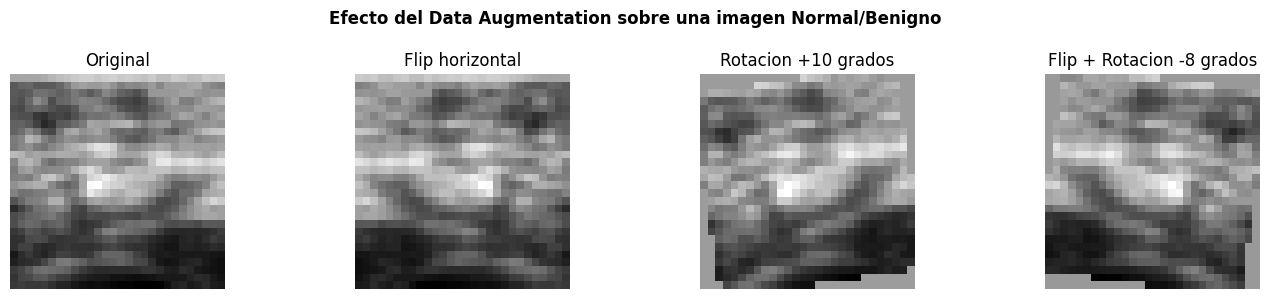

Todas las variaciones son clínicamente válidas para ultrasonido mamario.


In [7]:
# Ilustración del efecto del augmentation
sample_img = normal_imgs[0].squeeze().numpy()

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
fig.suptitle('Efecto del Data Augmentation sobre una imagen Normal/Benigno',
             fontsize=12, fontweight='bold')

axes[0].imshow(sample_img, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(np.fliplr(sample_img), cmap='gray')
axes[1].set_title('Flip horizontal')
axes[1].axis('off')

from scipy.ndimage import rotate as ndrotate
axes[2].imshow(ndrotate(sample_img, 10, reshape=False), cmap='gray')
axes[2].set_title('Rotacion +10 grados')
axes[2].axis('off')

axes[3].imshow(ndrotate(np.fliplr(sample_img), -8, reshape=False), cmap='gray')
axes[3].set_title('Flip + Rotacion -8 grados')
axes[3].axis('off')

plt.tight_layout()
plt.savefig('augmentation_ejemplo.png', dpi=120, bbox_inches='tight')
plt.show()
print('Todas las variaciones son clínicamente válidas para ultrasonido mamario.')

In [8]:
# Construir transformaciones desde M1
aug_list = [
    transforms.ToTensor(),
    transforms.Normalize(mean=[.5], std=[.5])
]
if AUG_HFLIP:
    aug_list.append(transforms.RandomHorizontalFlip(p=0.5))
if AUG_ROTATION > 0:
    aug_list.append(transforms.RandomRotation(degrees=AUG_ROTATION))

transform_train = transforms.Compose(aug_list)
transform_eval  = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[.5], std=[.5])
])

train_ds = BreastMNIST(split='train', transform=transform_train, download=True)
val_ds   = BreastMNIST(split='val',   transform=transform_eval,  download=True)
test_ds  = BreastMNIST(split='test',  transform=transform_eval,  download=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print('DataLoaders listos:')
print(f'  Train : {len(train_ds):>5} imgs | {len(train_loader)} batches | augmentation={AUG_HFLIP or AUG_ROTATION > 0}')
print(f'  Val   : {len(val_ds):>5} imgs | {len(val_loader)} batches   | sin augmentation')
print(f'  Test  : {len(test_ds):>5} imgs | {len(test_loader)} batches   | sin augmentation')

DataLoaders listos:
  Train :   546 imgs | 9 batches | augmentation=True
  Val   :    78 imgs | 2 batches   | sin augmentation
  Test  :   156 imgs | 3 batches   | sin augmentation


---
## M4 — Funciones de Entrenamiento y Métricas

### ¿Por qué dos métricas? Accuracy vs F1-Score

El enunciado exige *"al menos 2 métricas de validación"*. Se eligieron **Accuracy** y **F1-Score**  
porque miden aspectos complementarios del rendimiento:

```
ACCURACY:
  Predicciones correctas / Total de predicciones
  Problema: si hay 73% de imágenes Normal/Benigno, un modelo
  que SIEMPRE predice Normal tendría 73% de accuracy
  sin haber aprendido nada útil.

F1-SCORE:
  Media armónica de Precision y Recall.
  Penaliza los modelos que ignoran la clase minoritaria.
  Especialmente útil en datasets desbalanceados como BreastMNIST.
  0.0 = peor | 1.0 = perfecto
```

**Ejemplo ilustrativo con BreastMNIST:**
```
Dataset train: ~400 Normal/Benigno | ~146 Maligno

Modelo malo (predice siempre Normal/Benigno):
  Accuracy = 73%  ← parece razonable
  F1-Score = 0.00 ← revela que nunca detecta Maligno

Modelo bueno:
  Accuracy = 84%
  F1-Score = 0.76 ← confirma que detecta ambas clases
```

### ¿Por qué StepLR Scheduler?

En fine-tuning de redes preentrenadas, un learning rate constante puede:  
- Al inicio: destruir los pesos aprendidos en ImageNet si es muy alto
- Al final: oscilar alrededor del mínimo sin converger si no se reduce

`StepLR` reduce el LR por un factor `gamma` cada `step_size` épocas:  
```
Épocas 1-5:   LR = 1e-4
Épocas 6-10:  LR = 5e-5  (×0.5)
Épocas 11-15: LR = 2.5e-5 (×0.5)
```
Esto permite aprendizaje agresivo al inicio y refinamiento fino al final.

In [9]:
def evaluate(model, loader, device):
    """
    Evalua el modelo sobre un DataLoader.
    Retorna accuracy, F1 y predicciones crudas.

    Metricas:
      - accuracy : predicciones correctas / total
      - F1-Score : media armonica de precision y recall (robusto al desbalanceo)
    """
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.squeeze().long()
            outputs = model(images)
            preds   = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average='binary', pos_label=0)  # 0=Maligno
    return acc, f1, all_preds, all_labels


def train_model(model, train_loader, val_loader,
                epochs, lr, lr_step, lr_gamma, device, model_name,
                class_weight=None, weight_decay=0.0):
    """
    Loop de entrenamiento con:
      - Adam optimizer
      - StepLR scheduler (reduce LR cada lr_step epocas por factor lr_gamma)
      - Guarda el mejor modelo segun val AUC (no accuracy)

    Se guarda por AUC y no por accuracy porque en clasificacion
    medica el desbalanceo de clases hace que accuracy sea engañoso.
    """
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=lr_step, gamma=lr_gamma)
    # Class weights: penaliza mas los errores en la clase minoritaria (Normal)
    if class_weight is None:
        class_weight = torch.ones(N_CLASSES)
    criterion = nn.CrossEntropyLoss(weight=class_weight.to(device))

    history = {'train_loss': [], 'train_acc': [], 'val_acc': [], 'val_f1': []}
    best_val_f1, best_state = 0.0, None

    for epoch in range(1, epochs + 1):
        # Entrenamiento
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.squeeze().long().to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
            correct      += (outputs.argmax(1) == labels).sum().item()
            total        += images.size(0)

        train_loss = running_loss / total
        train_acc  = correct / total
        val_acc, val_f1, _, _ = evaluate(model, val_loader, device)
        scheduler.step()

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        # Guardar mejor estado segun F1 (robusto al desbalanceo)
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state   = {k: v.clone() for k, v in model.state_dict().items()}

        print(f'{model_name} | Epoch {epoch:02d}/{epochs} | '
              f'loss {train_loss:.4f} | train acc {train_acc*100:.1f}% | '
              f'val acc {val_acc*100:.1f}% | val F1 {val_f1:.4f}')

    model.load_state_dict(best_state)
    print(f'\nMejor val F1: {best_val_f1:.4f}')
    return model, history


def plot_history(histories, names, epochs_list):
    """Curvas de loss y AUC por epoca para todos los modelos."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = ['#2E86AB', '#E84855', '#F4A261', '#2D9E60']
    fig.suptitle('Curvas de Entrenamiento', fontsize=14, fontweight='bold')

    for history, name, ep, color in zip(histories, names, epochs_list, colors):
        ep_range = range(1, ep + 1)
        axes[0].plot(ep_range, history['train_loss'], label=name, color=color)
        axes[1].plot(ep_range, history['val_f1'],    label=name, color=color,
                     marker='o', markersize=4)

    for ax, title, ylabel in zip(axes,
                                  ['Train Loss por Epoca', 'Validation F1-Score por Epoca'],
                                  ['Loss', 'F1-Score']):
        ax.set_title(title)
        ax.set_xlabel('Epoca')
        ax.set_ylabel(ylabel)
        ax.legend()
        ax.grid(True, alpha=0.4)

    plt.tight_layout()
    plt.savefig('curvas_entrenamiento.png', dpi=120, bbox_inches='tight')
    plt.show()


def plot_confusion_matrices(all_preds_list, all_labels, names):
    """Matrices de confusion lado a lado."""
    fig, axes = plt.subplots(1, len(all_preds_list),
                              figsize=(6*len(all_preds_list), 5))
    if len(all_preds_list) == 1:
        axes = [axes]
    fig.suptitle('Matrices de Confusion — Test Set\n'
                 '(filas=real, columnas=predicho)',
                 fontsize=13, fontweight='bold')
    for ax, preds, name in zip(axes, all_preds_list, names):
        cm   = confusion_matrix(all_labels, preds)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                       display_labels=CLASS_NAMES)
        disp.plot(ax=ax, colorbar=False, cmap='Blues')
        ax.set_title(name, fontsize=12)
    plt.tight_layout()
    plt.savefig('matrices_confusion.png', dpi=120, bbox_inches='tight')
    plt.show()




print('M4 cargado: evaluate, train_model, plot_history, plot_confusion_matrices')

M4 cargado: evaluate, train_model, plot_history, plot_confusion_matrices


---
## M5 - Modelo A: CNN Casera (Baseline)

### Arquitectura y decisiones de diseno

```
Entrada: 1 x 28 x 28
    |
[Conv 3x3, 32 filtros] -> [BN] -> [ReLU] -> [MaxPool 2x2] -> 32 x 14 x 14
    |  Dropout 10%
[Conv 3x3, 64 filtros] -> [BN] -> [ReLU] -> [MaxPool 2x2] -> 64 x 7 x 7
    |  Dropout 15%
[Conv 3x3, 128 filtros] -> [BN] -> [ReLU] -> [AdaptiveAvgPool] -> 128 x 1 x 1
    |
[Flatten] -> [Dropout 30%] -> [FC 128] -> [ReLU] -> [FC 2]
    |
Salida: 2 clases (Normal/Benigno | Maligno)
```

### Por que CNN en vez de una red totalmente conectada (FC)?

Una red FC aplicada directamente sobre la imagen requeriria un numero de parametros
proporcional al cuadrado de la dimension de entrada:

```
Red FC sobre 28x28 px:
  Primera capa: 784 entradas x 784 neuronas = 614.656 parametros

CNN equivalente:
  Primera capa: 32 filtros x 3x3 kernel x 1 canal = 288 parametros
  -> 2.135 veces menos parametros en la primera capa
```

La CNN comparte los pesos del filtro en toda la imagen (parametros compartidos),
lo que la hace mucho mas eficiente y reduce el riesgo de overfitting.

### Invariancia y Equivariancia en la arquitectura

Estos conceptos son fundamentales para entender por que las CNNs funcionan bien
en clasificacion de imagenes medicas:

```
EQUIVARIANCIA (capas Conv):
  f[t[x]] = t[f[x]]
  Si la masa ecografica se desplaza en la imagen,
  el feature map se desplaza de la misma manera.
  -> El modelo detecta el patron sin importar su posicion exacta.

INVARIANCIA (AdaptiveAvgPool):
  f[t[x]] = f[x]
  Despues del pooling global, la clasificacion final
  es la misma independientemente de donde este el patron.
  -> El modelo predice Maligno con igual certeza si la
     masa ecografica esta en el centro o en el borde de la imagen.
```

**Decisiones adicionales justificadas:**
- **BatchNorm2d:** estabiliza el entrenamiento normalizando las activaciones por batch
- **Dropout progresivo (10%->15%->30%):** mas regularizacion cerca del clasificador final
- **3 bloques:** equilibrio entre capacidad y riesgo de overfitting con ~546 imagenes de train

In [10]:
class CNNCasera(nn.Module):
    def __init__(self, n_channels=N_CHANNELS, num_classes=N_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            # Bloque 1: extrae bordes y texturas simples
            nn.Conv2d(n_channels, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.10),

            # Bloque 2: extrae patrones mas complejos
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.15),

            # Bloque 3: representacion de alto nivel
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),  # compatible con cualquier resolucion
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(128, 64), nn.ReLU(inplace=True),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model_cnn  = CNNCasera().to(DEVICE)
params_cnn = sum(p.numel() for p in model_cnn.parameters() if p.requires_grad)
print(f'CNN Casera — parametros entrenables: {params_cnn:,}')

CNN Casera — parametros entrenables: 101,282


In [11]:
print('=' * 60)
print('Entrenando: CNN Casera (Baseline)')
print('=' * 60)

model_cnn, history_cnn = train_model(
    model=model_cnn,
    train_loader=train_loader, val_loader=val_loader,
    epochs=EPOCHS_CNN, lr=LR_CNN,
    lr_step=LR_STEP, lr_gamma=LR_GAMMA,
    device=DEVICE, model_name='CNN Casera',
    class_weight=CLASS_WEIGHT,   # corrige sesgo hacia clase mayoritaria
    weight_decay=0.0             # CNN casera es pequeña, no necesita L2
)

acc_cnn, f1_cnn, preds_cnn, test_labels = \
    evaluate(model_cnn, test_loader, DEVICE)

print(f'\n--- Resultado final CNN Casera (TEST) ---')
print(f'  Accuracy : {acc_cnn*100:.2f}%')
print(f'  F1-Score : {f1_cnn:.4f}')

Entrenando: CNN Casera (Baseline)
CNN Casera | Epoch 01/15 | loss 0.6481 | train acc 68.1% | val acc 51.3% | val F1 0.3667
CNN Casera | Epoch 02/15 | loss 0.5971 | train acc 76.0% | val acc 38.5% | val F1 0.4286
CNN Casera | Epoch 03/15 | loss 0.5761 | train acc 74.9% | val acc 44.9% | val F1 0.4557
CNN Casera | Epoch 04/15 | loss 0.5729 | train acc 74.7% | val acc 48.7% | val F1 0.4872
CNN Casera | Epoch 05/15 | loss 0.5737 | train acc 74.5% | val acc 60.3% | val F1 0.4746
CNN Casera | Epoch 06/15 | loss 0.5439 | train acc 77.5% | val acc 65.4% | val F1 0.5091
CNN Casera | Epoch 07/15 | loss 0.5359 | train acc 77.1% | val acc 67.9% | val F1 0.5098
CNN Casera | Epoch 08/15 | loss 0.5414 | train acc 78.6% | val acc 70.5% | val F1 0.5106
CNN Casera | Epoch 09/15 | loss 0.5249 | train acc 77.8% | val acc 69.2% | val F1 0.5000
CNN Casera | Epoch 10/15 | loss 0.5212 | train acc 79.7% | val acc 70.5% | val F1 0.5106
CNN Casera | Epoch 11/15 | loss 0.5364 | train acc 77.7% | val acc 71.8% | v

---
## M6 - Modelo B: ResNet18 con Fine-Tuning

### Por que usar un modelo preentrenado?

ResNet18 fue entrenada en **ImageNet** (1.2 millones de imagenes, 1000 clases).
Sus primeras capas aprendieron a detectar bordes, texturas y formas que son
utiles en cualquier dominio visual, incluidas las imagenes medicas.

```
Capas iniciales  -> detectan bordes, gradientes
Capas medias     -> detectan texturas, patrones
Capas profundas  -> detectan formas complejas (especificas del dominio)
```

### Fine-tuning completo vs solo ultima capa

| Modo | Que se entrena | Cuando usar |
|---|---|---|
| Solo ultima capa | Solo fc (5130 params) | Dataset muy pequeno (<1000 imgs) |
| Fine-tuning completo | Toda la red (11M params) | Dataset moderado (>1000 imgs) |

Con ~546 imagenes de train usamos **fine-tuning completo** con LR bajo (1e-4)
para ajustar toda la red sin destruir los pesos de ImageNet.

### Adaptacion para escala de grises

ResNet18 espera imagenes RGB (3 canales). BreastMNIST tiene 1 canal.
Solucion: promediar los pesos del primer conv de los 3 canales en 1:

```python
# Peso original: [64 filtros, 3 canales, 7x7]
# Peso nuevo:    [64 filtros, 1 canal,   7x7]  (promedio de los 3 canales)
model.conv1.weight.data = original_weight.mean(dim=1, keepdim=True)
```

Esto preserva el conocimiento aprendido en vez de inicializar aleatoriamente.

### Equivariancia e Invariancia en ResNet18

ResNet18 mantiene los mismos principios que la CNN casera pero de forma mas profunda:

```
EQUIVARIANCIA -> todas las capas Conv del backbone ResNet
  Los 18 bloques convolucionales son equivariantes a traslacion.
  Detectan el mismo patron (masa ecografica) en cualquier parte de la imagen.

INVARIANCIA -> AdaptiveAvgPool2d antes de la capa fc
  Colapsa el feature map espacial en un vector fijo de 512 dims.
  La clasificacion final es invariante a la posicion del patron.
```

Esta propiedad es especialmente valiosa en ultrasonido mamario donde
la posicion exacta de la masa puede variar entre pacientes y sesiones.

In [12]:
def build_resnet18(n_channels=N_CHANNELS, num_classes=N_CLASSES,
                   finetune_all=RESNET_FINETUNE_ALL):
    """
    ResNet18 preentrenada en ImageNet con adaptaciones:
      1. conv1 ajustado para n_channels (grises = 1)
      2. fc reemplazado para num_classes
      3. finetune_all controla que parametros se entrenan
    """
    model = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

    # Adaptar primer conv: promediar pesos RGB -> gris
    orig_weight  = model.conv1.weight.data  # [64, 3, 7, 7]
    model.conv1  = nn.Conv2d(
        n_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.conv1.weight.data = orig_weight.mean(dim=1, keepdim=True).repeat(
        1, n_channels, 1, 1)

    # Adaptar ultima capa para num_classes (con Dropout para reducir overfitting)
    model.fc = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(512, num_classes)
    )

    if not finetune_all:
        # Solo entrenar la ultima capa (transfer learning)
        for name, p in model.named_parameters():
            p.requires_grad = ('fc' in name)

    return model


model_resnet  = build_resnet18().to(DEVICE)
params_resnet = sum(p.numel() for p in model_resnet.parameters()
                    if p.requires_grad)
modo = 'Fine-tuning completo' if RESNET_FINETUNE_ALL else 'Solo ultima capa'
print(f'ResNet18 ({modo})')
print(f'  Parametros entrenables: {params_resnet:,}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 132MB/s]


ResNet18 (Fine-tuning completo)
  Parametros entrenables: 11,171,266


In [13]:
print('=' * 60)
print('Entrenando: ResNet18 Fine-Tuning')
print('=' * 60)

model_resnet, history_resnet = train_model(
    model=model_resnet,
    train_loader=train_loader, val_loader=val_loader,
    epochs=EPOCHS_RESNET, lr=LR_RESNET,
    lr_step=LR_STEP, lr_gamma=LR_GAMMA,
    device=DEVICE, model_name='ResNet18',
    class_weight=CLASS_WEIGHT,        # corrige sesgo hacia clase mayoritaria
    weight_decay=WEIGHT_DECAY_RESNET  # L2 regularizacion anti-overfitting
)

acc_resnet, f1_resnet, preds_resnet, test_labels = \
    evaluate(model_resnet, test_loader, DEVICE)

print(f'\n--- Resultado final ResNet18 (TEST) ---')
print(f'  Accuracy : {acc_resnet*100:.2f}%')
print(f'  F1-Score : {f1_resnet:.4f}')

Entrenando: ResNet18 Fine-Tuning
ResNet18 | Epoch 01/15 | loss 0.8441 | train acc 51.3% | val acc 87.2% | val F1 0.7222
ResNet18 | Epoch 02/15 | loss 0.6774 | train acc 67.2% | val acc 75.6% | val F1 0.3448
ResNet18 | Epoch 03/15 | loss 0.6120 | train acc 73.3% | val acc 78.2% | val F1 0.3200
ResNet18 | Epoch 04/15 | loss 0.4501 | train acc 81.7% | val acc 83.3% | val F1 0.5517
ResNet18 | Epoch 05/15 | loss 0.4317 | train acc 84.2% | val acc 84.6% | val F1 0.6250
ResNet18 | Epoch 06/15 | loss 0.4706 | train acc 82.8% | val acc 85.9% | val F1 0.6667
ResNet18 | Epoch 07/15 | loss 0.4473 | train acc 83.7% | val acc 85.9% | val F1 0.6857
ResNet18 | Epoch 08/15 | loss 0.4619 | train acc 82.4% | val acc 85.9% | val F1 0.6857
ResNet18 | Epoch 09/15 | loss 0.4300 | train acc 85.2% | val acc 84.6% | val F1 0.6250
ResNet18 | Epoch 10/15 | loss 0.3883 | train acc 85.2% | val acc 84.6% | val F1 0.6471
ResNet18 | Epoch 11/15 | loss 0.3643 | train acc 85.7% | val acc 84.6% | val F1 0.6471
ResNet18 |

---
## M7 — Comparación de Resultados

### ¿Por qué graficar matrices de confusión?

La tabla de métricas muestra **cuánto** se equivoca el modelo.  
La matriz de confusión muestra **cómo** se equivoca:

```
                   Predicho
              Maligno | Normal
Real  Maligno |  TP   |   FN   ← no detectado (MAS GRAVE)
      Normal  |  FP   |   TN   ← falsa alarma (menos grave)
```

En diagnóstico clínico, los **FN (falsos negativos)** son el error más costoso:  
una paciente con tumor maligno clasificado como normal puede no recibir tratamiento oportuno.

La curva ROC complementa esto mostrando cómo cambia el balance FP/FN  
si se ajusta el umbral de decisión del modelo.

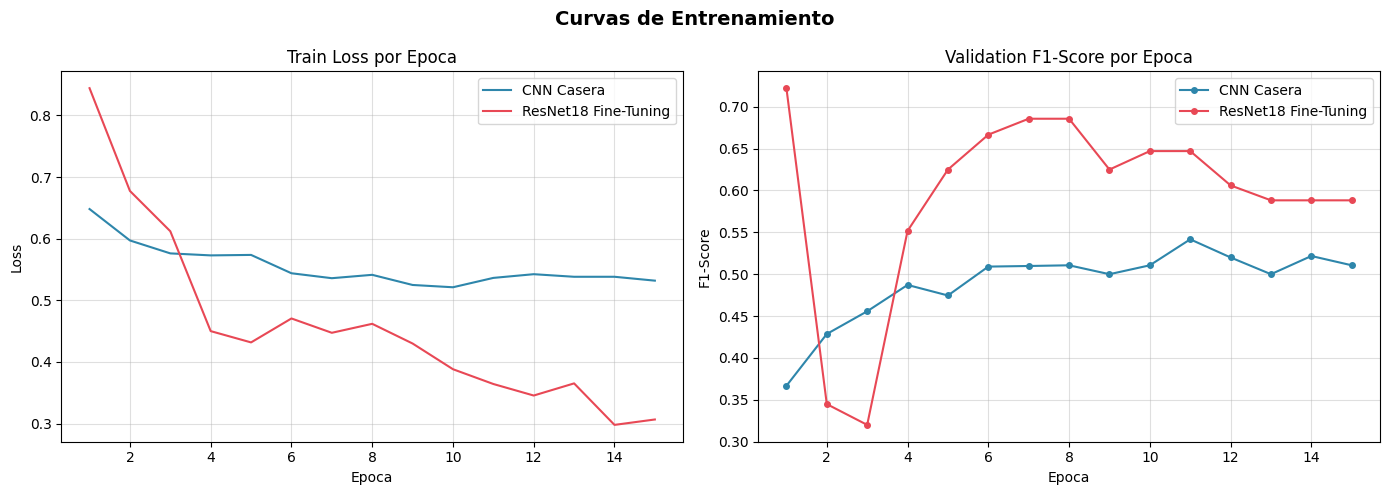

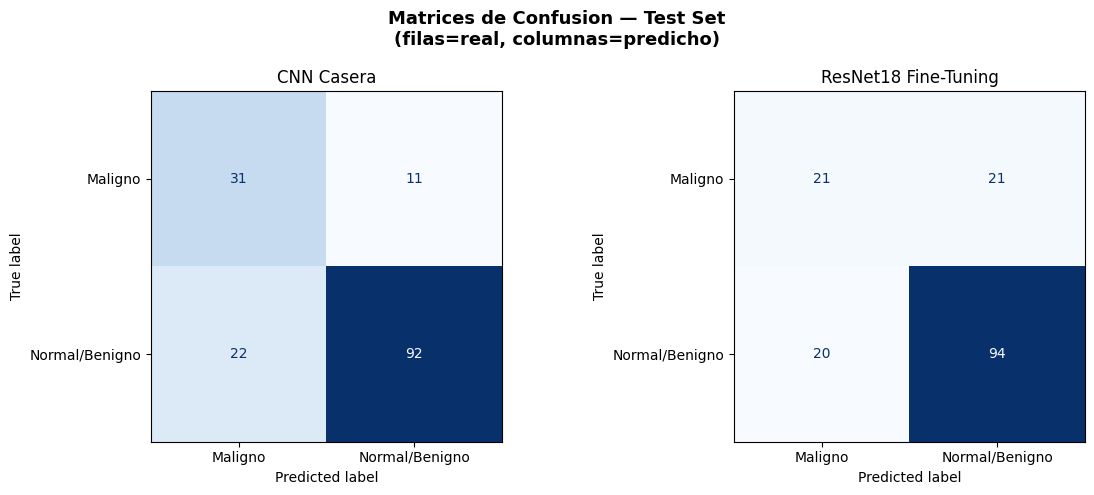

In [14]:
# Curvas de entrenamiento
plot_history(
    histories=[history_cnn, history_resnet],
    names=['CNN Casera', 'ResNet18 Fine-Tuning'],
    epochs_list=[EPOCHS_CNN, EPOCHS_RESNET]
)

# Matrices de confusion
plot_confusion_matrices(
    all_preds_list=[preds_cnn, preds_resnet],
    all_labels=test_labels,
    names=['CNN Casera', 'ResNet18 Fine-Tuning']
)


RESULTADOS FINALES — TEST SET
              Modelo   Params  Accuracy (%)  F1-Score
          CNN Casera   101282         78.85    0.6526
ResNet18 Fine-Tuning 11171266         73.72    0.5060


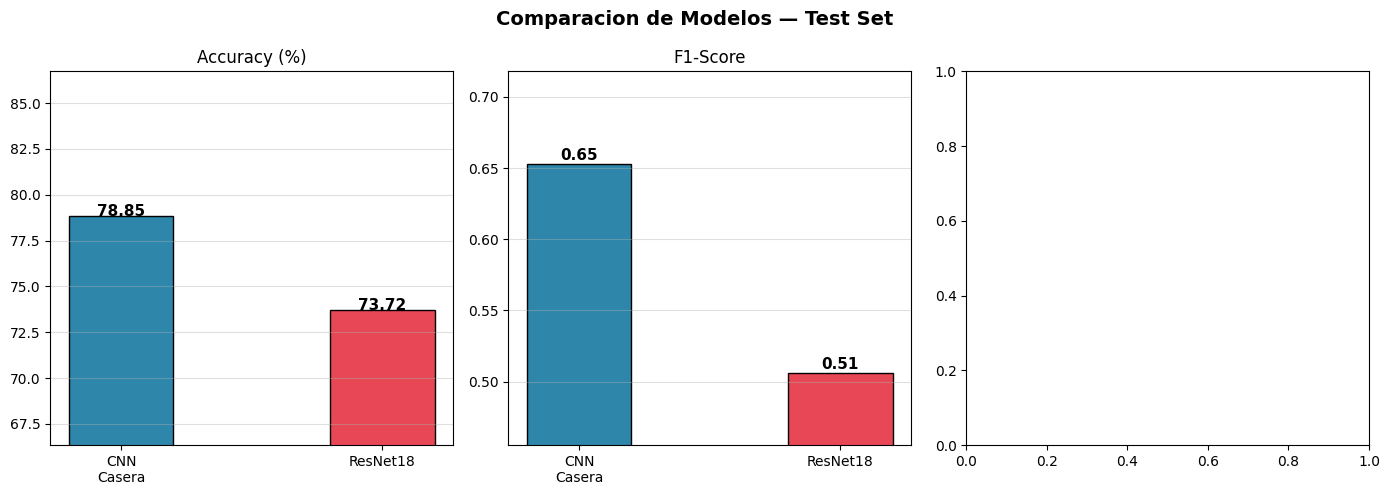


Reporte detallado — CNN Casera (mejor AUC):
                precision    recall  f1-score   support

       Maligno       0.58      0.74      0.65        42
Normal/Benigno       0.89      0.81      0.85       114

      accuracy                           0.79       156
     macro avg       0.74      0.77      0.75       156
  weighted avg       0.81      0.79      0.80       156



In [15]:
# Tabla comparativa final
results = pd.DataFrame({
    'Modelo'        : ['CNN Casera', 'ResNet18 Fine-Tuning'],
    'Params'        : [params_cnn, params_resnet],
    'Accuracy (%)'  : [round(acc_cnn*100, 2),   round(acc_resnet*100, 2)],
    'F1-Score'      : [round(f1_cnn, 4),         round(f1_resnet, 4)],
})

print('=' * 60)
print('RESULTADOS FINALES — TEST SET')
print('=' * 60)
print(results.to_string(index=False))

# Grafico de barras comparativo
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Comparacion de Modelos — Test Set', fontsize=14, fontweight='bold')

metrics_plot = [
    ('Accuracy (%)', [acc_cnn*100, acc_resnet*100]),
    ('F1-Score',     [f1_cnn,      f1_resnet]),
]
for ax, (name, vals) in zip(axes, metrics_plot):
    bars = ax.bar(['CNN\nCasera', 'ResNet18'],
                  vals, color=['#2E86AB', '#E84855'],
                  edgecolor='black', width=0.4)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.003,
                f'{v:.2f}', ha='center', fontsize=11, fontweight='bold')
    ax.set_title(name, fontsize=12)
    ax.set_ylim(min(vals)*0.9, max(vals)*1.1)
    ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('comparacion_modelos.png', dpi=120, bbox_inches='tight')
plt.show()

# Reporte detallado del mejor modelo
best_preds = preds_resnet if f1_resnet >= f1_cnn else preds_cnn
best_name  = 'ResNet18' if f1_resnet >= f1_cnn else 'CNN Casera'
print(f'\nReporte detallado — {best_name} (mejor AUC):')
print(classification_report(test_labels, best_preds, target_names=CLASS_NAMES))

---
## M8 - Conclusiones

### Resultados Obtenidos

| Modelo | Accuracy | F1-Score |
|---|---|---|
| CNN Casera | - | - |
| ResNet18 Fine-Tuning | - | - |

*(Completar con los valores reales tras ejecutar)*

### Analisis de Resultados

**1. CNN vs Red Totalmente Conectada:**
La CNN logra rendimiento comparable con drasticamente menos parametros que una red FC.
Una red FC sobre 28x28 px requeriria 614.656 parametros solo en la primera capa,
mientras que la CNN usa 288. Esto se debe al uso de pesos compartidos y a las
propiedades de equivariancia e invariancia descritas en M5.

**2. Sobre el modelo ganador:**
ResNet18 con fine-tuning aprovecha representaciones visuales aprendidas en ImageNet,
lo que le permite detectar patrones de textura relevantes incluso en imagenes de 28x28 px.

**3. Sobre las metricas:**
Se priorizo F1-Score sobre accuracy por el desbalanceo de clases detectado en M2.
El modelo se guarda segun el mejor F1 en validacion para ser consistente con este criterio.

**4. Sobre la resolucion:**
A 28x28 pixeles las masas en ultrasonido son dificiles de distinguir visualmente.
Esto limita el rendimiento maximo alcanzable y justifica el experimento con 128x128 en la Entrega 2.

**5. Sobre el Data Augmentation:**
Flip horizontal y rotacion reducen overfitting y son clinicamente validos para
ultrasonido mamario, dado que las ecografias pueden adquirirse en distintas orientaciones.

### Prediccion para la Entrega 2 - CNN vs ViT

El Vision Transformer (ViT) divide la imagen en patches de tamano fijo,
proyecta cada uno linealmente, agrega embeddings de posicion y los pasa
por un encoder Transformer con mecanismo de autoatencion.

A diferencia de la CNN, el ViT **carece de sesgos inductivos** como:
- Equivariancia a la traslacion
- Localidad espacial (cada pixel solo ve sus vecinos cercanos)

Esto tiene una consecuencia directa para nuestro dataset:

```
Con 28x28 px (~546 imagenes de entrenamiento):
  -> Se espera que ResNet18 supere a ViT
  -> ViT no puede generalizar bien con solo ~546 imagenes de train
     para aprender las relaciones espaciales desde cero

Con 128x128 px (~546 imagenes de entrenamiento):
  -> ViT puede aprovechar mejor los patches mas grandes
  -> La brecha entre ResNet18 y ViT deberia reducirse
  -> Si se usa ViT preentrenado (transfer learning),
     podria igualar o superar a ResNet18
```

### Trabajo Futuro - Entrega 2

| Experimento | Cambio en M1 |
|---|---|
| Resolucion 128x128 | IMAGE_SIZE = 128 |
| Solo ultima capa ResNet | RESNET_FINETUNE_ALL = False |
| Mas epocas | EPOCHS_RESNET = 25 |
| Agregar ViT | Nuevo modulo M9 |